# Deep Learning Project 1: a residual CNN under 5M parameters

Team **jiaqi li nyu** (Jiaqi Li). This notebook shows the executed results behind the report. It only reads the
training logs, checkpoints and Kaggle receipts that `train.py` and the submission step produced; it does not train
anything. Running it regenerates every report figure in `report/figures/`.

Two kinds of accuracy appear below and are kept apart:
- **Validation accuracy**: the fixed seed-2026 split of 5,000 official training images (500 per class) that the
  model never trained on. It is computed here.
- **Kaggle test accuracy**: the hidden 2,000-image evaluation set, scored by Kaggle. We do not have its labels;
  the numbers come from the recorded Kaggle submission receipts.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.ticker import PercentFormatter

from analysis import (CLASSES, confusion, load_checkpoint_model, load_config, load_metrics, load_submissions,
                      validation_predictions)
from model import ARCHITECTURES, build_model, multiply_accumulates, parameter_count

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
FIGURES = Path("report/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False})
BASELINE, IMPROVED = "baseline-100ep", "improved100-resnet18-64-352"
print("torch", torch.__version__, "| device", device)

torch 2.15.0 | device mps


## Data and split
The 50,000 official training images (5,000 per class) are split once, stratified with seed 2026. Normalization
statistics use only the 45,000 training images. The 2,000 hidden test images are only ever passed through the
final model to write `submission.csv`.

In [2]:
audit = json.loads(Path("data/cache/audit.json").read_text())
print("training split:", audit["training_split"], "| validation split:", audit["validation_split"],
      "| per-class validation counts:", audit["validation_class_counts"])
print("hidden test images:", audit["test_images"], "| test labels accessed:", audit["test_labels_accessed"])
print("normalization mean:", np.round(audit["normalization_training_only_mean"], 4),
      "std:", np.round(audit["normalization_training_only_std"], 4))

training split: 45000 | validation split: 5000 | per-class validation counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
hidden test images: 2000 | test labels accessed: False
normalization mean: [0.4915 0.4823 0.4468] std: [0.2471 0.2435 0.2615]


## Architectures
Every candidate uses the course's residual block `ReLU(S(x) + F(x))`, where `F = conv-BN-ReLU-conv-BN` and `S` is
the identity, or a 1x1 conv + BN when the shape changes. The final model, `resnet18-64-352`, keeps ResNet-18's
full-width first three stages and trims stage 4 to a single 352-channel block.

In [3]:
for name in ARCHITECTURES:
    candidate = build_model(name)
    spec = ARCHITECTURES[name]
    print(f"{name:16s} widths={spec['widths']!s:22s} blocks={spec['depths']!s:14s} "
          f"params={parameter_count(candidate):>9,}  MACs/image={multiply_accumulates(candidate) / 1e6:5.0f}M")
final_model = build_model("resnet18-64-352")
print(final_model)
print(f"\nNumber of trainable parameters in the final model: {parameter_count(final_model):,} (limit 5,000,000)")

resnet18-w32     widths=(32, 64, 128, 256)     blocks=(2, 2, 2, 2)   params=2,797,610  MACs/image=  139M
resnet18-w42     widths=(42, 84, 168, 336)     blocks=(2, 2, 2, 2)   params=4,815,940  MACs/image=  240M
resnet18-64-352  widths=(64, 128, 256, 352)    blocks=(2, 2, 2, 1)   params=4,797,002  MACs/image=  453M
resnet20-x4      widths=(64, 128, 256)         blocks=(3, 3, 3)      params=4,327,754  MACs/image=  648M
CifarResNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (blocks): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    

## Training recipes
The baseline and improved runs use the same split, seed and SGD/Nesterov optimizer. The settings that differ
(the baseline run predates some of these config keys; its values are the code defaults in `configs/baseline.json`):

In [4]:
base = {**json.loads(Path("configs/baseline.json").read_text()), **load_config(BASELINE)}
improved = load_config(IMPROVED)
for key in ("arch", "epochs", "batch_size", "lr", "lr_per_step", "weight_decay", "bn_weight_decay", "pipeline",
            "padding_mode", "cutout", "label_smoothing", "ema_decay", "amp"):
    print(f"{key:16s} baseline={base[key]!s:16s} improved={improved[key]}")

arch             baseline=resnet18-w32     improved=resnet18-64-352
epochs           baseline=100              improved=100
batch_size       baseline=128              improved=256
lr               baseline=0.1              improved=0.2
lr_per_step      baseline=False            improved=True
weight_decay     baseline=0.0005           improved=0.0005
bn_weight_decay  baseline=True             improved=False
pipeline         baseline=batched          improved=trivialaugment
padding_mode     baseline=constant         improved=reflect
cutout           baseline=0                improved=16
label_smoothing  baseline=0.0              improved=0.1
ema_decay        baseline=0.0              improved=0.999
amp              baseline=none             improved=bf16


## Training curves
With the improved recipe, training accuracy on augmented batches stays well below validation accuracy. That is the
effect of TrivialAugment, Cutout and label smoothing. The EMA weights lead the raw weights while the learning rate is high.

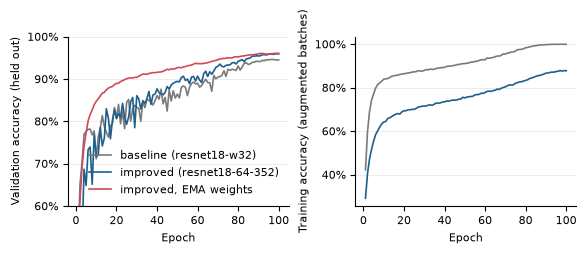

In [5]:
baseline_metrics, improved_metrics = load_metrics(BASELINE), load_metrics(IMPROVED)
fig, axes = plt.subplots(1, 2, figsize=(5.75, 2.2), layout="constrained")
for metrics, label, color in ((baseline_metrics, "baseline (resnet18-w32)", "#7a7a7a"),
                              (improved_metrics, "improved (resnet18-64-352)", "#1f5f8b")):
    epochs = [r["epoch"] for r in metrics]
    axes[0].plot(epochs, [r["valid_accuracy"] for r in metrics], color=color, lw=1.2, label=label)
    axes[1].plot(epochs, [r["train_accuracy"] for r in metrics], color=color, lw=1.2, label=label)
axes[0].plot([r["epoch"] for r in improved_metrics], [r["ema_valid_accuracy"] for r in improved_metrics],
             color="#d1495b", lw=1.2, label="improved, EMA weights")
axes[0].set_ylim(0.6, 1.0)
axes[0].set_ylabel("Validation accuracy (held out)")
axes[1].set_ylabel("Training accuracy (augmented batches)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y", color="#e5e5e5", lw=.5)
axes[0].legend(frameon=False, loc="lower right")
fig.savefig(FIGURES / "curves.pdf")
fig.savefig(FIGURES / "curves.png", dpi=200)
plt.show()

## Held-out results at the same 100-epoch budget
These are the logged last-epoch values. The final model's numbers are recomputed from its checkpoint further below.

In [6]:
rows = [("baseline", BASELINE, baseline_metrics[-1].get("valid_accuracy"), None, None),
        ("improved", IMPROVED, improved_metrics[-1]["valid_accuracy"], improved_metrics[-1]["ema_valid_accuracy"],
         improved_metrics[-1]["tta_valid_accuracy"])]
print(f"{'recipe':10s} {'run':30s} {'params':>10s} {'raw':>7s} {'EMA':>7s} {'EMA+flip':>9s}")
for recipe, run, raw, ema, tta in rows:
    fmt = lambda v: f"{v:.2%}" if v is not None else "-"
    print(f"{recipe:10s} {run:30s} {load_config(run)['parameter_count']:>10,} {fmt(raw):>7s} {fmt(ema):>7s} {fmt(tta):>9s}")
hours = lambda m: sum(r["train_seconds"] + r["valid_seconds"] + r["checkpoint_seconds"] for r in m) / 3600
print(f"\nwall-clock: baseline {hours(baseline_metrics):.2f} h, improved {hours(improved_metrics):.2f} h "
      f"(Apple M5 Pro GPU; improved uses bf16 autocast)")

recipe     run                                params     raw     EMA  EMA+flip
baseline   baseline-100ep                  2,797,610  94.48%       -         -
improved   improved100-resnet18-64-352     4,797,002  95.90%  96.02%    96.42%

wall-clock: baseline 0.29 h, improved 0.54 h (Apple M5 Pro GPU; improved uses bf16 autocast)


## Speed on the Apple GPU (MPS)
This is the saved short benchmark (`benchmark_models.py`): 20 timed steps at batch 256 with arbitrary labels and a
synchronization after every step. It understates absolute throughput, but it shows the relative effect of precision.
Its third model, `resnet18-64-352`, has 1.9x the compute of `resnet18-w42` for the same parameter budget.

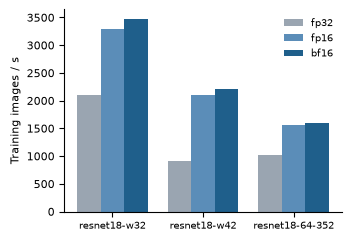

resnet18-w32     none    2108 img/s
resnet18-w32     bf16    3473 img/s
resnet18-w32     fp16    3292 img/s
resnet18-w42     none     913 img/s
resnet18-w42     bf16    2215 img/s
resnet18-w42     fp16    2110 img/s
resnet18-64-352  none    1022 img/s
resnet18-64-352  bf16    1601 img/s
resnet18-64-352  fp16    1552 img/s
full training epochs (logged): resnet18-64-352 bf16 ≈ 2575 img/s, baseline fp32 batch 128 ≈ 4531 img/s


In [7]:
bench = json.loads(Path("artifacts/model_speed_benchmark.json").read_text())["results"]
archs = list(dict.fromkeys(r["arch"] for r in bench))
amps = ["none", "fp16", "bf16"]
fig, ax = plt.subplots(figsize=(3.4, 2.3), layout="constrained")
width = 0.26
for i, amp in enumerate(amps):
    values = [next(r["images_per_second"] for r in bench if r["arch"] == a and r["amp"] == amp) for a in archs]
    ax.bar(np.arange(len(archs)) + (i - 1) * width, values, width, label={"none": "fp32"}.get(amp, amp),
           color=("#9aa5b1", "#5b8db8", "#1f5f8b")[i])
ax.set_xticks(np.arange(len(archs)), archs, fontsize=7)
ax.set_ylabel("Training images / s")
ax.legend(frameon=False, fontsize=7)
fig.savefig(FIGURES / "speed.pdf")
fig.savefig(FIGURES / "speed.png", dpi=200)
plt.show()
for r in bench:
    print(f"{r['arch']:16s} {r['amp']:5s} {r['images_per_second']:6.0f} img/s")
print(f"full training epochs (logged): resnet18-64-352 bf16 ≈ {np.median([r['train_images_per_second'] for r in improved_metrics[1:]]):.0f} img/s, "
      f"baseline fp32 batch 128 ≈ {np.median([r['train_images_per_second'] for r in baseline_metrics[1:]]):.0f} img/s")

## Final model: re-evaluation from its checkpoint
We reload `runs/improved100-resnet18-64-352/last.pt` (EMA weights) and recompute held-out accuracy with and without
horizontal-flip test-time augmentation. This is the checkpoint behind the Kaggle submission below.

In [8]:
model, checkpoint = load_checkpoint_model(f"runs/{IMPROVED}/last.pt", device)
assert parameter_count(model) <= 5_000_000
results = {}
for tta in ("none", "flip"):
    predicted, labels = validation_predictions(model, device, tta)
    results[tta] = (predicted, labels)
    print(f"held-out validation accuracy, EMA weights, TTA={tta}: {(predicted == labels).mean():.2%}")
baseline_model, _ = load_checkpoint_model(f"runs/{BASELINE}/last.pt", device)
base_predicted, base_labels = validation_predictions(baseline_model, device, "none")
print(f"held-out validation accuracy, baseline: {(base_predicted == base_labels).mean():.2%}")

held-out validation accuracy, EMA weights, TTA=none: 96.02%


held-out validation accuracy, EMA weights, TTA=flip: 96.42%


held-out validation accuracy, baseline: 94.48%


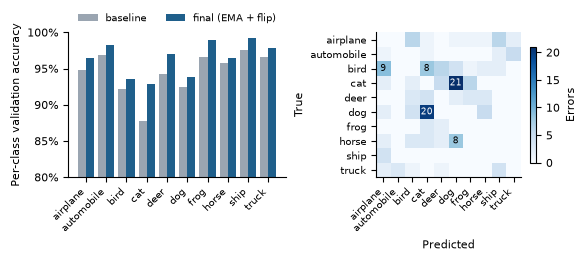

cat        baseline 87.8% -> final 92.8%
bird       baseline 92.2% -> final 93.6%
dog        baseline 92.4% -> final 93.8%
airplane   baseline 94.8% -> final 96.4%
horse      baseline 95.8% -> final 96.4%
deer       baseline 94.2% -> final 97.0%
truck      baseline 96.6% -> final 97.8%
automobile baseline 96.8% -> final 98.2%
frog       baseline 96.6% -> final 99.0%
ship       baseline 97.6% -> final 99.2%
largest confusions (true -> predicted): [('cat', 'dog', 21), ('dog', 'cat', 20), ('bird', 'airplane', 9), ('bird', 'cat', 8)]


In [9]:
final_predicted, labels = results["flip"]
per_class = [(final_predicted[labels == c] == c).mean() for c in range(10)]
base_per_class = [(base_predicted[base_labels == c] == c).mean() for c in range(10)]
fig, axes = plt.subplots(1, 2, figsize=(5.75, 2.5), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1]})
x = np.arange(10)
axes[0].bar(x - 0.2, base_per_class, 0.4, color="#9aa5b1", label="baseline")
axes[0].bar(x + 0.2, per_class, 0.4, color="#1f5f8b", label="final (EMA + flip)")
axes[0].set_xticks(x, CLASSES, rotation=45, ha="right", fontsize=7)
axes[0].set_ylim(0.8, 1.0)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Per-class validation accuracy")
axes[0].legend(frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
matrix = confusion(final_predicted, labels)
off = matrix.copy()
np.fill_diagonal(off, 0)
image = axes[1].imshow(off, cmap="Blues")
axes[1].set_xticks(x, CLASSES, rotation=45, ha="right", fontsize=7)
axes[1].set_yticks(x, CLASSES, fontsize=7)
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
for i, j in zip(*np.nonzero(off >= 8)):
    axes[1].text(j, i, off[i, j], ha="center", va="center", fontsize=6.5, color="white" if off[i, j] > off.max() / 2 else "black")
fig.colorbar(image, ax=axes[1], shrink=0.8, label="Errors")
fig.savefig(FIGURES / "per_class.pdf")
fig.savefig(FIGURES / "per_class.png", dpi=200)
plt.show()
for c in np.argsort(per_class):
    print(f"{CLASSES[c]:10s} baseline {base_per_class[c]:.1%} -> final {per_class[c]:.1%}")
largest = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:4], off.shape))[0]
print("largest confusions (true -> predicted):", [(CLASSES[i], CLASSES[j], int(off[i, j])) for i, j in largest])

## Kaggle test accuracy and the submitted file
The hidden-test score below is copied from Kaggle's submission record, not computed locally. Kaggle splits the 2,000
test images 50/50 into public and private halves; the private score appears only after the competition closes.

In [10]:
for receipt in load_submissions():
    private = "not yet released" if receipt["private_score"] is None else f"{receipt['private_score']:.2%}"
    print(f"submission {receipt['submission_ref']} ({receipt['submitted_utc']}): {receipt['arch']}, "
          f"{receipt['parameter_count']:,} params, weights={receipt['weights']}, TTA={receipt['tta']}")
    print(f"  local held-out validation {receipt['local_heldout_valid_accuracy']:.2%} | "
          f"Kaggle public test accuracy {receipt['public_score']:.2%} | private {private}")
final = load_submissions()[-1]
print(f"\nFINAL TEST ACCURACY (Kaggle public leaderboard): {final['public_score']:.2%}")
print(f"NUMBER OF PARAMETERS: {final['parameter_count']:,}")
check = subprocess.run([sys.executable, "check_submission.py", final["file"]], capture_output=True, text=True, check=True)
print(check.stdout)

submission 57784806 (2026-10-29T23:21:48Z): resnet18-64-352, 4,797,002 params, weights=ema, TTA=flip
  local held-out validation 96.42% | Kaggle public test accuracy 86.30% | private not yet released

FINAL TEST ACCURACY (Kaggle public leaderboard): 86.30%
NUMBER OF PARAMETERS: 4,797,002


{
  "csv": "runs/improved100-resnet18-64-352/submission.csv",
  "rows": 2000,
  "ids_match_sample_submission": true,
  "labels_valid": true,
  "csv_sha256": "721c074806ecf920df8e4c0a1bcdf2b1b872a6849d3b8713432573db3592afc7",
  "checkpoint": "runs/improved100-resnet18-64-352/last.pt",
  "arch": "resnet18-64-352",
  "parameter_count": 4797002,
  "weights": "ema",
  "tta": "flip",
  "predicted_class_counts": [
    178,
    208,
    194,
    214,
    191,
    213,
    187,
    204,
    208,
    203
  ],
  "kaggle_receipts_for_this_file": [
    {
      "submission_ref": 57784806,
      "status": "COMPLETE",
      "public_score": 0.863,
      "private_score": null
    }
  ]
}

